# 07 · Selección de variables y CatBoost: entregas D y F (JAE)

**Objetivo:** documentar con trazabilidad las dos últimas mejoras de la
competencia, que se construyeron con scripts exploratorios cerca del cierre:

- **Entrega D:** el conjunto JAE + interacciones (notebook 06) sin
  `disposable_income_clip` ni `total_late`, mezclado con el modelo FE.
- **Entrega F:** la entrega D mezclada por rangos con CatBoost (70 % / 30 %).

También se documenta una idea descartada: las restricciones monótonas en
XGBoost.

**Trazabilidad.** Igual que en los notebooks 05 y 06: cada iteración cambia
una sola cosa, lleva antes un bloque de comentarios con la iteración previa
(dataset, hiperparámetros y AUC) y `verificar_previa()` comprueba que el AUC
del comentario coincide con el calculado. La traza se guarda en
`data/processed/jae/traza_07.json`.

**Dos particiones.** Elegir variables o pesos de mezcla mirando los mismos
5 folds con los que se mide el AUC sesga el resultado a favor de lo elegido
(*overfitting* a la partición). Por eso cada decisión se confirma también en
una **partición independiente** (`StratifiedKFold`, semilla 2024), que no se
usó para elegir nada.

**Resultado en Kaggle:** la entrega F fue la mejor del equipo en el
leaderboard público (0.88016) y el equipo mantuvo el tercer lugar en el
privado.

## 0. Preparación

In [1]:
import json
import logging
import sys
import time
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from IPython.display import display
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from xgboost import XGBClassifier

# El notebook vive en notebooks/: se agrega src/ al path para importar los módulos
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from evaluation import RANDOM_STATE, get_cv, read_log  # noqa: E402
from evaluation.oof_jae import ResultadoCV, registrar_en_bitacora  # noqa: E402
from features.engineering_jae import (  # noqa: E402
    ID,
    TARGET,
    FeatureConfig,
    build_preprocessor,
    prepare_fixed,
)
from features.features import prepare  # noqa: E402

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

SEMILLA = RANDOM_STATE  # semilla compartida del equipo (985)
SEMILLAS = [985, 1, 2, 3, 4]  # semillas de las entregas
SEMILLAS_RAPIDAS = [985, 1]  # semillas de los análisis (selección, controles)
SALIDA = ROOT / "data" / "processed" / "jae"
INICIO = time.time()

## 1. Datos, conjuntos de variables y particiones

| Conjunto | Origen | Contenido |
| --- | --- | --- |
| **JAE + interacciones** | `FeatureConfig(for_trees=True, impute_for_trees=False, interactions=True)` | 27 variables (notebook 06) |
| **FE** | `features.features.prepare()` | 28 variables (segundo miembro de las mezclas) |

La configuración JAE para árboles sin imputar **no aprende nada de los
datos** (solo cálculos fijos y selección de columnas), así que se puede
transformar una sola vez fuera de la validación cruzada sin data leakage.

In [2]:
train_raw = pd.read_csv(ROOT / "data/raw/train.csv")
test_raw = pd.read_csv(ROOT / "data/raw/test.csv")
muestra = pd.read_csv(ROOT / "data/raw/sample_submission.csv")
y = train_raw[TARGET]

CONFIG_JAE_INT = FeatureConfig(
    for_trees=True, impute_for_trees=False, interactions=True
)
preprocesador = build_preprocessor(CONFIG_JAE_INT)
X27 = preprocesador.fit_transform(prepare_fixed(train_raw.drop(columns=[TARGET, ID])))
X27_test = preprocesador.transform(prepare_fixed(test_raw.drop(columns=[ID])))
X_fe = prepare(train_raw)
X_fe_test = prepare(test_raw)
assert list(X27.columns) == list(X27_test.columns), "JAE: train y test no coinciden"
assert X27.shape[1] == 27, "Se esperaban las 27 variables del notebook 06"

PARTICIONES = {
    "equipo": list(get_cv().split(X27, y)),
    "independiente": list(
        StratifiedKFold(n_splits=5, shuffle=True, random_state=2024).split(X27, y)
    ),
}
DATASET_27 = "JAE + interacciones (27 variables, NaN nativo)"
DATASET_FE = f"FE: features.prepare() ({X_fe.shape[1]} variables, NaN nativo)"
print(f"train: {len(train_raw):,} filas · test: {len(test_raw):,} filas")
print(DATASET_27, "·", DATASET_FE)

train: 105,000 filas · test: 45,000 filas
JAE + interacciones (27 variables, NaN nativo) · FE: features.prepare() (28 variables, NaN nativo)


## 2. Herramientas de trazabilidad

In [3]:
PARAMETROS_2B = {
    "max_depth": 6,
    "min_child_weight": 10,
    "subsample": 0.6,
    "colsample_bytree": 0.7,
    "reg_lambda": 10.0,
    "gamma": 0.5,
}
LEARNING_RATE = 0.01
ARBOLES_JAE = 764  # notebook 05, iteración 1
ARBOLES_FE = 777  # notebook 05, iteración 3
TOLERANCIA_AUC = 5e-5

traza: list[dict] = []
resultados: dict[str, ResultadoCV] = {}


def xgboost(semilla: int, **parametros: object) -> XGBClassifier:
    """Crea el XGBoost de los notebooks 05 y 06 (parámetros 2b, lr 0.01).

    Args:
        semilla: Semilla del modelo.
        **parametros: Parámetros que reemplazan a los de 2b.

    Returns:
        Clasificador sin ajustar.
    """
    base = {
        "n_estimators": ARBOLES_JAE,
        "learning_rate": LEARNING_RATE,
        "eval_metric": "auc",
        "tree_method": "hist",
        "n_jobs": -1,
        "random_state": semilla,
        **PARAMETROS_2B,
    }
    base.update(parametros)
    return XGBClassifier(**base)


def oof_semillas(
    crear: Callable[[int], object],
    X: pd.DataFrame,
    folds: list[tuple[np.ndarray, np.ndarray]],
    semillas: list[int],
) -> np.ndarray:
    """Predicciones fuera de fold promediando varias semillas.

    Args:
        crear: Función que recibe una semilla y devuelve el modelo sin ajustar.
        X: Variables de entrada.
        folds: Partición (índices de entrenamiento y validación).
        semillas: Semillas a promediar.

    Returns:
        Probabilidad OOF de cada fila de ``train``.
    """
    oof = np.zeros(len(y))
    for entrenamiento, validacion in folds:
        oof[validacion] = np.mean(
            [
                crear(s)
                .fit(X.iloc[entrenamiento], y.iloc[entrenamiento])
                .predict_proba(X.iloc[validacion])[:, 1]
                for s in semillas
            ],
            axis=0,
        )
    return oof


def auc_folds(
    oof: np.ndarray, folds: list[tuple[np.ndarray, np.ndarray]]
) -> np.ndarray:
    """AUC de validación de cada fold.

    Args:
        oof: Predicciones fuera de fold.
        folds: Partición con la que se generaron.

    Returns:
        Arreglo con un AUC por fold.
    """
    return np.array([roc_auc_score(y.iloc[va], oof[va]) for _, va in folds])


def rangos(oof: np.ndarray, folds: list[tuple[np.ndarray, np.ndarray]]) -> np.ndarray:
    """Convierte las predicciones en rangos relativos dentro de cada fold.

    Mezclar rangos en lugar de probabilidades evita que un modelo con
    probabilidades más extremas domine la mezcla. El AUC solo depende del
    orden, así que no se pierde nada.

    Args:
        oof: Predicciones fuera de fold.
        folds: Partición con la que se generaron.

    Returns:
        Rango de cada fila dividido entre el tamaño de su fold.
    """
    salida = np.zeros(len(oof))
    for _, va in folds:
        salida[va] = rankdata(oof[va]) / len(va)
    return salida


def resultado(nombre: str, oof: np.ndarray) -> ResultadoCV:
    """Construye el resultado de la partición del equipo a partir del OOF.

    Args:
        nombre: Nombre del experimento.
        oof: Predicciones fuera de fold con la partición del equipo.

    Returns:
        Resultado con el AUC por fold; el AUC de entrenamiento queda en ``NaN``.
    """
    folds = PARTICIONES["equipo"]
    return ResultadoCV(
        nombre=nombre,
        auc_folds=auc_folds(oof, folds),
        auc_train_folds=np.full(len(folds), np.nan),
        oof=oof,
        auc_oof=float(roc_auc_score(y, oof)),
        tiempo_s=0.0,
        curvas=[(y.iloc[va].to_numpy(), oof[va]) for _, va in folds],
    )


def diferencia(a: np.ndarray, b: np.ndarray) -> dict[str, object]:
    """Resume una comparación pareada fold por fold.

    Args:
        a: AUC por fold del experimento.
        b: AUC por fold de la referencia.

    Returns:
        Diferencia media, error estándar y folds en que gana ``a``.
    """
    d = a - b
    return {
        "Δ": round(float(d.mean()), 5),
        "error estándar": round(float(d.std(ddof=1) / np.sqrt(len(d))), 5),
        "folds en que gana": f"{int((d > 0).sum())}/{len(d)}",
    }


def verificar_previa(clave: str, auc_comentado: float) -> None:
    """Comprueba que el AUC anotado en el comentario coincide con el calculado.

    Args:
        clave: Clave de la iteración en ``resultados``.
        auc_comentado: AUC de validación escrito en el comentario.

    Raises:
        AssertionError: Si la diferencia supera ``TOLERANCIA_AUC``.
    """
    calculado = resultados[clave].auc_media
    assert abs(calculado - auc_comentado) <= TOLERANCIA_AUC, (
        f"El comentario dice {auc_comentado:.5f} y la iteración {clave} "
        f"dio {calculado:.5f}: actualizar el bloque de trazabilidad"
    )
    print(f"✅ Iteración {clave}: AUC {calculado:.5f} (coincide con el comentario)")


def registrar_iteracion(
    clave: str, previa: str | None, cambio: str, dataset: str, modelo: str
) -> pd.DataFrame:
    """Agrega una iteración a la traza y la compara fold por fold con la previa.

    Args:
        clave: Clave de la iteración en ``resultados``.
        previa: Clave de la iteración de la que parte; ``None`` para la base.
        cambio: Único cambio introducido respecto a la previa.
        dataset: Conjunto de variables usado.
        modelo: Modelo e hiperparámetros que la distinguen.

    Returns:
        Tabla con la iteración y su comparación pareada contra la previa.
    """
    r = resultados[clave]
    fila = {
        "iteración": clave,
        "experimento": r.nombre,
        "parte de": previa or "—",
        "cambio": cambio,
        "dataset": dataset,
        "modelo": modelo,
        "AUC": round(r.auc_media, 5),
        "desv": round(r.auc_std, 5),
        "AUC OOF": round(r.auc_oof, 5),
    }
    if previa is not None:
        comparacion = diferencia(r.auc_folds, resultados[previa].auc_folds)
        fila.update({f"{k} vs previa": v for k, v in comparacion.items()})
    traza.append(fila)
    return pd.DataFrame([fila]).set_index("iteración").T

## 3. Iteración 0: punto de partida (notebooks 05 y 06)
Se leen las predicciones OOF guardadas de la entrega B y del modelo JAE +
interacciones (5 semillas) y se verifica que reproducen la bitácora.

In [4]:
# ─── TRAZABILIDAD · PUNTO DE PARTIDA ────────────────────────────────────────
# Entrega B:        jae_5_entrega_b_mezcla (notebook 05)
#   Dataset:        JAE (23 variables) + FE (28 variables), mezcla 50/50
#   AUC (CV):       0.86663 · Kaggle público: 0.88012
# JAE + interac.:   jae_6_interacciones_semillas (notebook 06)
#   Dataset:        JAE + interacciones (27 variables, NaN nativo)
#   Hiperparámetros: learning_rate=0.01 + parámetros 2b; 764 árboles;
#                   promedio de 5 semillas (985, 1, 2, 3, 4)
#   AUC (CV):       0.86653 ± 0.00287
# ────────────────────────────────────────────────────────────────────────────
oof_05 = pd.read_parquet(SALIDA / "oof_mejora_05.parquet")
oof_06 = pd.read_parquet(SALIDA / "oof_interacciones_06.parquet")
for tabla in (oof_05, oof_06):
    assert (tabla[ID].to_numpy() == train_raw[ID].to_numpy()).all(), "Orden distinto"
resultados["B"] = resultado(
    "jae_5_entrega_b_mezcla", oof_05["oof_entrega_b"].to_numpy()
)
resultados["FE"] = resultado("jae_4_xgboost_fe_semillas", oof_05["oof_fe"].to_numpy())
resultados["0"] = resultado(
    "jae_6_interacciones_semillas", oof_06["oof_jae_interacciones"].to_numpy()
)
verificar_previa("B", 0.86663)
verificar_previa("FE", 0.86663)
verificar_previa("0", 0.86653)
registrar_iteracion(
    "0",
    None,
    "JAE + interacciones (notebook 06)",
    DATASET_27,
    f"XGBoost 2b, lr=0.01, {ARBOLES_JAE} árboles, 5 semillas",
)

✅ Iteración B: AUC 0.86663 (coincide con el comentario)
✅ Iteración FE: AUC 0.86663 (coincide con el comentario)
✅ Iteración 0: AUC 0.86653 (coincide con el comentario)


iteración,0
experimento,jae_6_interacciones_semillas
parte de,—
cambio,JAE + interacciones (notebook 06)
dataset,"JAE + interacciones (27 variables, NaN nativo)"
modelo,"XGBoost 2b, lr=0.01, 764 árboles, 5 semillas"
AUC,0.86653
desv,0.00287
AUC OOF,0.86642


## 4. Selección de variables

### 4.1 Quitar una variable a la vez
Para cada una de las 27 variables se entrena el mismo modelo sin ella y se
compara fold por fold contra el modelo completo. Se usan 2 semillas para que
el análisis sea manejable; la base con 2 semillas tiene su propio AUC.

In [5]:
columnas_27 = list(X27.columns)
folds_equipo = PARTICIONES["equipo"]


def xgb_rapido(columnas: list[str], folds: list, **parametros: object) -> np.ndarray:
    """AUC por fold del XGBoost 2b con 2 semillas sobre un subconjunto de columnas.

    Args:
        columnas: Variables que se usan.
        folds: Partición.
        **parametros: Parámetros que reemplazan a los de 2b.

    Returns:
        AUC por fold.
    """
    oof = oof_semillas(
        lambda s: xgboost(s, **parametros), X27[columnas], folds, SEMILLAS_RAPIDAS
    )
    return auc_folds(oof, folds)


bases = {
    nombre: xgb_rapido(columnas_27, folds) for nombre, folds in PARTICIONES.items()
}
print({nombre: round(float(b.mean()), 5) for nombre, b in bases.items()})

filas = []
for variable in columnas_27:
    sin = xgb_rapido([c for c in columnas_27 if c != variable], folds_equipo)
    filas.append({"variable": variable, **diferencia(sin, bases["equipo"])})
quitar_una = (
    pd.DataFrame(filas)
    .rename(columns={"Δ": "Δ al quitarla", "folds en que gana": "folds en que mejora"})
    .sort_values("Δ al quitarla", ascending=False)
    .reset_index(drop=True)
)
print(f"Tiempo acumulado: {time.time() - INICIO:.0f} s")
display(quitar_una)

{'equipo': 0.86649, 'independiente': 0.86597}


Tiempo acumulado: 1520 s


,variable,Δ al quitarla,error estándar,folds en que mejora
0,disposable_income_clip,0.00020,0.00011,4/5
1,total_late,0.00015,0.00012,3/5
2,thin_file,0.00014,0.00010,3/5
3,late_severity,0.00014,0.00012,2/5
4,income_zero,0.00014,0.00009,4/5
5,dependents_missing,0.00013,0.00010,4/5
6,income_placeholder,0.00013,0.00009,4/5
7,non_re_lines,0.00013,0.00010,3/5
8,late_x_util,0.00012,0.00011,4/5
9,util_zero,0.00012,0.00008,3/5


In [6]:
correlacion = X27.corr(method="spearman").abs()
pares = pd.DataFrame(
    [
        {"variable 1": a, "variable 2": b, "|Spearman|": correlacion.loc[a, b]}
        for i, a in enumerate(columnas_27)
        for b in columnas_27[i + 1 :]
        if correlacion.loc[a, b] > 0.9
    ]
).sort_values("|Spearman|", ascending=False)
display(pares.round(3))

,variable 1,variable 2,|Spearman|
3,max_late,total_late,0.999
7,total_late,late_severity,0.998
4,max_late,late_severity,0.996
5,util_clip,age_x_util,0.980
6,open_lines,non_re_lines,0.973
1,late_x_util,total_late,0.966
2,late_x_util,late_severity,0.965
0,late_x_util,max_late,0.965


**Lectura:** solo cuatro variables son claramente indispensables: al
quitarlas el AUC baja en los 5 folds (`age` −0.00205, `late_sentinel`
−0.00058, `real_estate` −0.00049 y `debt_amount` −0.00041). En cambio,
quitar casi cualquier otra **sube** el AUC entre +0.00002 y +0.00020 (21 de
27 variables), aunque cada mejora por separado está dentro del ruido.
Encabezan el ranking `disposable_income_clip` (+0.00020) y `total_late`
(+0.00015). La tabla de correlaciones muestra la redundancia: `max_late`,
`total_late` y `late_severity` son casi la misma variable (Spearman de 0.996
a 0.999), y lo mismo ocurre con `util_clip` y `age_x_util` (0.980) y con
`open_lines` y `non_re_lines` (0.973).

### 4.2 Controles, grupos y eliminación acumulada en las dos particiones
- **Controles:** el modelo completo con `colsample_bytree` en 1.0 y 0.5,
  para probar si el efecto viene del muestreo de columnas.
- **Grupos por significado:** atrasos redundantes, indicadores débiles y
  derivadas del ingreso.
- **Eliminación acumulada:** quitar las *k* primeras variables del ranking
  de la sección 4.1, con *k* de 1 a 5.

Todo se mide en la partición del equipo y en la independiente.

In [7]:
GRUPOS = {
    "atrasos redundantes": ["total_late", "late_severity"],
    "indicadores débiles": [
        "thin_file",
        "income_zero",
        "dependents_missing",
        "income_placeholder",
        "util_gt1",
        "util_zero",
        "income_missing",
    ],
    "derivadas del ingreso": ["disposable_income_clip", "per_dependent_income_clip"],
}
ranking = quitar_una["variable"].tolist()
variantes: dict[str, tuple[list[str], dict]] = {
    "control: colsample_bytree=1.0": (columnas_27, {"colsample_bytree": 1.0}),
    "control: colsample_bytree=0.5": (columnas_27, {"colsample_bytree": 0.5}),
    **{
        f"sin {nombre}": ([c for c in columnas_27 if c not in quitar], {})
        for nombre, quitar in GRUPOS.items()
    },
    **{
        f"sin las {k} primeras del ranking": (
            [c for c in columnas_27 if c not in ranking[:k]],
            {},
        )
        for k in range(1, 6)
    },
}
filas = []
for nombre, (columnas, parametros) in variantes.items():
    fila = {"variante": nombre, "variables": len(columnas)}
    for particion, folds in PARTICIONES.items():
        comparacion = diferencia(
            xgb_rapido(columnas, folds, **parametros), bases[particion]
        )
        fila.update({f"{k} ({particion})": v for k, v in comparacion.items()})
    filas.append(fila)
seleccion = pd.DataFrame(filas).set_index("variante")
print(f"Ranking (primeras 5): {ranking[:5]}")
print(f"Tiempo acumulado: {time.time() - INICIO:.0f} s")
display(seleccion)

Ranking (primeras 5): ['disposable_income_clip', 'total_late', 'thin_file', 'late_severity', 'income_zero']
Tiempo acumulado: 2005 s


,variables,Δ (equipo),error estándar (equipo),folds en que gana (equipo),Δ (independiente),error estándar (independiente),folds en que gana (independiente)
variante,,,,,,,
control: colsample_bytree=1.0,27,-0.00011,0.00017,2/5,-0.00017,0.00010,1/5
control: colsample_bytree=0.5,27,0.00019,0.00010,4/5,0.00002,0.00008,4/5
sin atrasos redundantes,25,0.00003,0.00015,2/5,-0.00011,0.00009,1/5
sin indicadores débiles,20,0.00005,0.00009,2/5,-0.00003,0.00009,2/5
sin derivadas del ingreso,25,0.00012,0.00010,3/5,0.00016,0.00013,3/5
sin las 1 primeras del ranking,26,0.00020,0.00011,4/5,0.00019,0.00016,4/5
sin las 2 primeras del ranking,25,0.00033,0.00014,5/5,0.00019,0.00015,4/5
sin las 3 primeras del ranking,24,0.00020,0.00011,4/5,0.00023,0.00008,5/5
sin las 4 primeras del ranking,23,0.00011,0.00021,2/5,0.00013,0.00018,3/5


**Lectura:** 
- **El efecto viene del muestreo de columnas.** Con `colsample_bytree=1.0`
  el modelo empeora en las dos particiones; con 0.5 mejora en la del equipo
  (+0.00019) pero no en la independiente (+0.00002). Quitar variables
  redundantes funciona mejor que cambiar el muestreo: cada árbol ve con más
  frecuencia a las variables que sí aportan.
- **Quitar grupos completos no sirve:** los atrasos redundantes y los
  indicadores débiles empeoran en la partición independiente.
- **La mejor selección es quitar las 2 primeras del ranking**
  (`disposable_income_clip` y `total_late`): +0.00033 en la partición del
  equipo (5 de 5 folds) y +0.00019 en la independiente (4 de 5). Es la única
  variante que mejora de forma clara en las dos.
- **Quitar más no ayuda:** con 3 variables la partición independiente sube un
  poco (+0.00023), pero la del equipo baja a +0.00020; con 4 y 5 la mejora
  se diluye en las dos (2 de 5 folds). La decisión de *k* = 2 se tomó antes
  de evaluar *k* = 4 y 5, y estos resultados la confirman.

### 4.3 Iteración 1: JAE con 25 variables
Se quitan `disposable_income_clip` y `total_late` y se repite el modelo de
la iteración 0 con sus 5 semillas.

In [8]:
# ─── TRAZABILIDAD · ITERACIÓN PREVIA (0) ────────────────────────────────────
# Experimento:      jae_6_interacciones_semillas (notebook 06)
# Dataset:          JAE + interacciones (27 variables, NaN nativo)
# Hiperparámetros:  learning_rate=0.01 + parámetros 2b; 764 árboles;
#                   promedio de 5 semillas
# AUC previo (CV):  0.86653 ± 0.00287
# ─── ESTA ITERACIÓN (1) ─────────────────────────────────────────────────────
# Cambio:           se quitan disposable_income_clip y total_late (27 → 25)
# Se mantiene:      hiperparámetros, 764 árboles, 5 semillas y partición
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("0", 0.86653)

QUITAR = ["disposable_income_clip", "total_late"]
columnas_25 = [c for c in columnas_27 if c not in QUITAR]
X25, X25_test = X27[columnas_25], X27_test[columnas_25]
DATASET_25 = (
    "JAE + interacciones sin disposable_income_clip ni total_late (25 variables)"
)
oof_25 = oof_semillas(lambda s: xgboost(s), X25, folds_equipo, SEMILLAS)
resultados["1"] = resultado("jae_8_seleccion_25_semillas", oof_25)
registrar_iteracion(
    "1",
    "0",
    "se quitan disposable_income_clip y total_late",
    DATASET_25,
    f"XGBoost 2b, lr=0.01, {ARBOLES_JAE} árboles, 5 semillas",
)

✅ Iteración 0: AUC 0.86653 (coincide con el comentario)


iteración,1
experimento,jae_8_seleccion_25_semillas
parte de,0
cambio,se quitan disposable_income_clip y total_late
dataset,JAE + interacciones sin disposable_income_clip ni total_late (25 variables)
modelo,"XGBoost 2b, lr=0.01, 764 árboles, 5 semillas"
AUC,0.86675
desv,0.00274
AUC OOF,0.86665
Δ vs previa,0.00022
error estándar vs previa,0.00013


### 4.4 Iteración 2: mezcla con FE (entrega D)
Misma receta que las entregas B y C: promedio 50/50 de probabilidades con el
modelo FE (5 semillas, 777 árboles).

In [9]:
# ─── TRAZABILIDAD · ITERACIÓN PREVIA (B) · ENTREGA B ────────────────────────
# Experimento:      jae_5_entrega_b_mezcla (notebook 05)
# Miembros:         JAE 23 variables (0.86638) + FE (0.86663), 50/50
# AUC previo (CV):  0.86663 · Kaggle público: 0.88012
# ─── PRIMER MIEMBRO DE LA MEZCLA (1) ────────────────────────────────────────
# Experimento:      jae_8_seleccion_25_semillas
# AUC (CV):         0.86675
# ─── ESTA ITERACIÓN (2) · ENTREGA D ─────────────────────────────────────────
# Cambio:           primer miembro de la mezcla: JAE 23 → JAE 25 (con las
#                   interacciones y sin disposable_income_clip ni total_late)
# Se mantiene:      modelo FE como segundo miembro; pesos 0.5 y 0.5
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("B", 0.86663)
verificar_previa("1", 0.86675)

resultados["2"] = resultado(
    "jae_9_entrega_d_mezcla", (oof_25 + resultados["FE"].oof) / 2
)
registrar_iteracion(
    "2",
    "B",
    "mezcla 50/50: JAE 23 → JAE 25 variables",
    f"{DATASET_25} + {DATASET_FE}",
    f"XGBoost 2b, lr=0.01, {ARBOLES_JAE} y {ARBOLES_FE} árboles, 5 semillas c/u",
)

✅ Iteración B: AUC 0.86663 (coincide con el comentario)
✅ Iteración 1: AUC 0.86675 (coincide con el comentario)


iteración,2
experimento,jae_9_entrega_d_mezcla
parte de,B
cambio,mezcla 50/50: JAE 23 → JAE 25 variables
dataset,"JAE + interacciones sin disposable_income_clip ni total_late (25 variables) + FE: features.prepare() (28 variables, NaN nativo)"
modelo,"XGBoost 2b, lr=0.01, 764 y 777 árboles, 5 semillas c/u"
AUC,0.86676
desv,0.00277
AUC OOF,0.86665
Δ vs previa,0.00013
error estándar vs previa,0.00006


**Lectura:** 
- **JAE con 25 variables (iteración 1): 0.86675**, +0.00022 sobre las 27
  variables (4 de 5 folds). Con 5 semillas la mejora se mantiene.
- **Entrega D (iteración 2): 0.86676**, +0.00013 sobre la entrega B (error
  estándar 0.00006, 4 de 5 folds).
- En Kaggle la entrega D obtuvo 0.87996, por debajo de la B (0.88012). La
  sección 7 muestra que ese resultado está dentro del ruido del puntaje
  público.

## 5. Idea descartada: restricciones monótonas
Se obliga a XGBoost a que el riesgo nunca baje cuando suben los atrasos o
la utilización y, en la primera variante, a que nunca suba con la edad. Es
una forma de regularización que a veces generaliza mejor.

In [10]:
# ─── TRAZABILIDAD · REFERENCIA ──────────────────────────────────────────────
# Modelo:           XGBoost JAE 25 variables (iteración 1), 2 semillas
# Cambio:           monotone_constraints en atrasos, utilización y edad
# ────────────────────────────────────────────────────────────────────────────
SUBE = [
    "late_30_59",
    "late_60_89",
    "late_90",
    "late_severity",
    "max_late",
    "late_x_util",
    "late_sentinel",
    "util_clip",
    "util_gt1",
]


def restricciones(con_edad: bool) -> str:
    """Arma el vector de restricciones monótonas para las 25 variables.

    Args:
        con_edad: Si se obliga además a que el riesgo no suba con la edad.

    Returns:
        Cadena con 1 (creciente), -1 (decreciente) o 0 por variable.
    """
    valores = [
        "1" if c in SUBE else "-1" if (con_edad and c == "age") else "0"
        for c in columnas_25
    ]
    return "(" + ",".join(valores) + ")"


filas = []
for nombre, con_edad in {
    "atrasos y utilización ↑, edad ↓": True,
    "solo atrasos y utilización ↑": False,
}.items():
    fila = {"variante": nombre}
    for particion, folds in PARTICIONES.items():
        base = auc_folds(oof_semillas(xgboost, X25, folds, SEMILLAS_RAPIDAS), folds)
        con = auc_folds(
            oof_semillas(
                lambda s: xgboost(s, monotone_constraints=restricciones(con_edad)),
                X25,
                folds,
                SEMILLAS_RAPIDAS,
            ),
            folds,
        )
        fila.update({f"{k} ({particion})": v for k, v in diferencia(con, base).items()})
    filas.append(fila)
print(f"Tiempo acumulado: {time.time() - INICIO:.0f} s")
display(pd.DataFrame(filas).set_index("variante"))

Tiempo acumulado: 2260 s


,Δ (equipo),error estándar (equipo),folds en que gana (equipo),Δ (independiente),error estándar (independiente),folds en que gana (independiente)
variante,,,,,,
"atrasos y utilización ↑, edad ↓",-0.00078,0.00018,0/5,-0.00053,0.00013,0/5
solo atrasos y utilización ↑,-0.00048,0.00017,1/5,-0.00038,0.00014,0/5


**Lectura:** las restricciones monótonas **empeoran en todos los casos**:
−0.00078 y −0.00048 en la partición del equipo y −0.00053 y −0.00038 en la
independiente, sin ganar casi ningún fold. El modelo sin restricciones
captura relaciones que no van en un solo sentido; el EDA ya mostraba, por
ejemplo, la forma de "U" del número de líneas de crédito. Se descarta.

## 6. CatBoost (entrega F)

Todos los XGBoost probados predicen casi lo mismo (Spearman ≈ 0.998), así
que mezclarlos ya no aporta. CatBoost construye árboles simétricos con un
esquema de *boosting* distinto y suele equivocarse en otros clientes. La
decisión de agregarlo como dependencia está en `docs/adr/0001-catboost.md`.

### 6.1 Iteración 3: CatBoost con las 25 variables JAE
El número de iteraciones se elige con *early stopping* sobre un 10 % interno
del primer fold de entrenamiento (+10 %, porque el modelo final ve todo el
fold).

In [11]:
# ─── TRAZABILIDAD · REFERENCIA (1) ──────────────────────────────────────────
# Experimento:      jae_8_seleccion_25_semillas
# Dataset:          JAE 25 variables · AUC (CV): 0.86675
# ─── ESTA ITERACIÓN (3) ─────────────────────────────────────────────────────
# Cambio:           modelo XGBoost → CatBoost (learning_rate=0.05, depth=6,
#                   l2_leaf_reg=5); 2 semillas en CV, 5 en test
# Se mantiene:      dataset y partición
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("1", 0.86675)

PARAMETROS_CATBOOST = {
    "learning_rate": 0.05,
    "depth": 6,
    "l2_leaf_reg": 5,
    "eval_metric": "AUC",
    "thread_count": -1,
    "verbose": 0,
    "allow_writing_files": False,
}
entrenamiento_0 = folds_equipo[0][0]
X_ajuste, X_parada, y_ajuste, y_parada = train_test_split(
    X25.iloc[entrenamiento_0],
    y.iloc[entrenamiento_0],
    test_size=0.1,
    stratify=y.iloc[entrenamiento_0],
    random_state=SEMILLA,
)
parada = CatBoostClassifier(
    **PARAMETROS_CATBOOST,
    iterations=4000,
    random_seed=SEMILLA,
    od_type="Iter",
    od_wait=200,
).fit(X_ajuste, y_ajuste, eval_set=(X_parada, y_parada))
ITERACIONES_CB = int(parada.get_best_iteration() * 1.1) + 1
print(f"Iteraciones de CatBoost: {ITERACIONES_CB}")


def catboost(semilla: int) -> CatBoostClassifier:
    """Crea el CatBoost de la entrega F.

    Args:
        semilla: Semilla del modelo.

    Returns:
        Clasificador sin ajustar.
    """
    return CatBoostClassifier(
        **PARAMETROS_CATBOOST, iterations=ITERACIONES_CB, random_seed=semilla
    )


oof_cb = {
    particion: oof_semillas(catboost, X25, folds, SEMILLAS_RAPIDAS)
    for particion, folds in PARTICIONES.items()
}
resultados["3"] = resultado("jae_10_catboost_seleccion_25", oof_cb["equipo"])
registrar_iteracion(
    "3",
    "1",
    "XGBoost → CatBoost",
    DATASET_25,
    f"CatBoost lr=0.05, depth=6, l2=5, {ITERACIONES_CB} iteraciones, 2 semillas",
)
espearman = pd.Series(oof_cb["equipo"]).corr(
    pd.Series(resultados["2"].oof), method="spearman"
)
print(f"Spearman entre CatBoost y la entrega D: {espearman:.4f}")

✅ Iteración 1: AUC 0.86675 (coincide con el comentario)


Iteraciones de CatBoost: 509


Spearman entre CatBoost y la entrega D: 0.9865


### 6.2 Iteración 4: mezcla por rangos de la entrega D con CatBoost (entrega F)
Se prueban pesos de 20 % a 50 % para CatBoost en las dos particiones. En la
partición independiente la entrega D se recalcula con 2 semillas.

In [12]:
# ─── TRAZABILIDAD · ITERACIÓN PREVIA (2) · ENTREGA D ────────────────────────
# Experimento:      jae_9_entrega_d_mezcla
# Miembros:         JAE 25 variables + FE, 50/50
# AUC previo (CV):  0.86676 · Kaggle público: 0.87996
# ─── SEGUNDO MIEMBRO DE LA MEZCLA (3) ───────────────────────────────────────
# Experimento:      jae_10_catboost_seleccion_25 · AUC (CV): 0.86618
# ─── ESTA ITERACIÓN (4) · ENTREGA F ─────────────────────────────────────────
# Cambio:           mezcla por rangos (1 − w) · D + w · CatBoost
# Se mantiene:      los dos modelos tal cual; no se reentrena nada
# ────────────────────────────────────────────────────────────────────────────
verificar_previa("2", 0.86676)
verificar_previa("3", 0.86618)

folds_ind = PARTICIONES["independiente"]
oof_d = {
    "equipo": resultados["2"].oof,
    "independiente": (
        oof_semillas(xgboost, X25, folds_ind, SEMILLAS_RAPIDAS)
        + oof_semillas(
            lambda s: xgboost(s, n_estimators=ARBOLES_FE),
            X_fe,
            folds_ind,
            SEMILLAS_RAPIDAS,
        )
    )
    / 2,
}
PESOS = [0.2, 0.3, 0.4, 0.5]
filas = []
for w in PESOS:
    fila = {"peso de CatBoost": w}
    for particion, folds in PARTICIONES.items():
        mezcla = (1 - w) * rangos(oof_d[particion], folds) + w * rangos(
            oof_cb[particion], folds
        )
        fila[f"AUC ({particion})"] = round(float(auc_folds(mezcla, folds).mean()), 5)
        comparacion = diferencia(
            auc_folds(mezcla, folds), auc_folds(oof_d[particion], folds)
        )
        fila.update({f"{k} vs D ({particion})": v for k, v in comparacion.items()})
    filas.append(fila)
pesos = pd.DataFrame(filas).set_index("peso de CatBoost")
print(f"Tiempo acumulado: {time.time() - INICIO:.0f} s")
display(pesos)

PESO_CB = 0.3
resultados["4"] = resultado(
    "jae_11_entrega_f_catboost_w30",
    (1 - PESO_CB) * rangos(oof_d["equipo"], folds_equipo)
    + PESO_CB * rangos(oof_cb["equipo"], folds_equipo),
)
verificar_previa("4", 0.86698)
registrar_iteracion(
    "4",
    "2",
    "mezcla por rangos: 70 % entrega D + 30 % CatBoost",
    f"{DATASET_25} + {DATASET_FE}",
    "XGBoost JAE + XGBoost FE + CatBoost JAE",
)

✅ Iteración 2: AUC 0.86676 (coincide con el comentario)
✅ Iteración 3: AUC 0.86618 (coincide con el comentario)


Tiempo acumulado: 2385 s


,AUC (equipo),Δ vs D (equipo),error estándar vs D (equipo),folds en que gana vs D (equipo),AUC (independiente),Δ vs D (independiente),error estándar vs D (independiente),folds en que gana vs D (independiente)
peso de CatBoost,,,,,,,,
0.2,0.86695,0.00019,0.00002,5/5,0.86628,0.00012,0.00007,4/5
0.3,0.86698,0.00022,0.00003,5/5,0.86627,0.00012,0.00010,4/5
0.4,0.86698,0.00022,0.00004,5/5,0.86623,0.00008,0.00013,3/5
0.5,0.86694,0.00019,0.00005,4/5,0.86615,0.00000,0.00016,3/5


✅ Iteración 4: AUC 0.86698 (coincide con el comentario)


iteración,4
experimento,jae_11_entrega_f_catboost_w30
parte de,2
cambio,mezcla por rangos: 70 % entrega D + 30 % CatBoost
dataset,"JAE + interacciones sin disposable_income_clip ni total_late (25 variables) + FE: features.prepare() (28 variables, NaN nativo)"
modelo,XGBoost JAE + XGBoost FE + CatBoost JAE
AUC,0.86698
desv,0.00275
AUC OOF,0.86698
Δ vs previa,0.00022
error estándar vs previa,0.00003


**Lectura:** 
- **CatBoost solo es peor** que el XGBoost JAE (0.86618 contra 0.86675),
  pero **se equivoca distinto**: su correlación de Spearman con la entrega D
  es 0.9865, contra ≈ 0.998 entre los XGBoost. Esa diversidad es la que
  aprovecha la mezcla.
- **Con 30 % de CatBoost (entrega F): 0.86698**, +0.00022 sobre la D en los
  5 folds (error estándar 0.00003) y +0.00035 sobre la B.
- **El peso se elige con las dos particiones.** En la del equipo 30 % y
  40 % empatan; en la independiente la mejora es de +0.00012 con 20 % y
  30 % y desaparece con 50 %. Se elige 30 %: el mejor punto de la partición
  del equipo que se sostiene en la independiente.
- En Kaggle la entrega F obtuvo **0.88016**, la mejor del equipo.

## 7. ¿Cuánto ruido tiene el puntaje público?
Se simula la parte pública de `test` tomando 2,000 muestras de `train` del
mismo tamaño (30 % y 50 % de las 45,000 filas) y se calcula el AUC de cada
entrega con sus predicciones OOF.

In [13]:
rng = np.random.default_rng(SEMILLA)
entregas_oof = {
    "F": resultados["4"].oof,
    "D": resultados["2"].oof,
    "B": resultados["B"].oof,
}
filas = []
for fraccion in (0.3, 0.5):
    n = int(len(test_raw) * fraccion)
    muestras = {k: [] for k in entregas_oof}
    for _ in range(2000):
        indices = rng.choice(len(y), n, replace=False)
        for k, oof in entregas_oof.items():
            muestras[k].append(roc_auc_score(y.iloc[indices], oof[indices]))
    simulado = pd.DataFrame(muestras)
    for otra in ("B", "D"):
        d = simulado["F"] - simulado[otra]
        filas.append(
            {
                "parte pública": f"{fraccion:.0%} ({n:,} filas)",
                "comparación": f"F − {otra}",
                "desv. del AUC de F": round(float(simulado["F"].std()), 4),
                "Δ medio": round(float(d.mean()), 5),
                "desv. de Δ": round(float(d.std()), 5),
                "P(F pierde en el público)": round(float((d < 0).mean()), 2),
            }
        )
display(pd.DataFrame(filas))

,parte pública,comparación,desv. del AUC de F,Δ medio,desv. de Δ,P(F pierde en el público)
0,"30% (13,500 filas)",F − B,0.0058,0.00046,0.00029,0.05
1,"30% (13,500 filas)",F − D,0.0058,0.00033,0.00025,0.09
2,"50% (22,500 filas)",F − B,0.0043,0.00046,0.00023,0.02
3,"50% (22,500 filas)",F − D,0.0043,0.00033,0.00019,0.04


**Lectura:** 
- **El AUC de un mismo modelo varía con una desviación estándar de 0.004 a
  0.006** según qué clientes caigan en la parte pública. Las diferencias
  entre los primeros lugares del leaderboard (≈ 0.0004) son mucho menores.
- **Entre entregas casi idénticas el ruido es menor, pero no nulo:** con
  una parte pública del 30 %, F pierde contra D en cerca del 9 % de los
  escenarios y contra B en cerca del 5 %. Que la D quedara por debajo de la
  B en el público era posible por puro azar.
- **Consecuencia:** las decisiones se toman con la validación cruzada (y una
  partición independiente), no con el puntaje público. El equipo mantuvo el
  tercer lugar del público en el privado, lo que indica que el modelo no
  estaba sobreajustado al leaderboard.

## 8. Traza completa, bitácora y entregas

,experimento,parte de,cambio,dataset,modelo,AUC,desv,AUC OOF,Δ vs previa,error estándar vs previa,folds en que gana vs previa,Δ vs B,folds en que gana a B
iteración,,,,,,,,,,,,,
0,jae_6_interacciones_semillas,—,JAE + interacciones (notebook 06),"JAE + interacciones (27 variables, NaN nativo)","XGBoost 2b, lr=0.01, 764 árboles, 5 semillas",0.86653,0.00287,0.86642,NaN,NaN,NaN,-0.00009,3/5
1,jae_8_seleccion_25_semillas,0,se quitan disposable_income_clip y total_late,JAE + interacciones sin disposable_income_clip ni total_late (25 variables),"XGBoost 2b, lr=0.01, 764 árboles, 5 semillas",0.86675,0.00274,0.86665,0.00022,0.00013,4/5,0.00012,4/5
2,jae_9_entrega_d_mezcla,B,mezcla 50/50: JAE 23 → JAE 25 variables,"JAE + interacciones sin disposable_income_clip ni total_late (25 variables) + FE: features.prepare() (28 variables, NaN nativo)","XGBoost 2b, lr=0.01, 764 y 777 árboles, 5 semillas c/u",0.86676,0.00277,0.86665,0.00013,0.00006,4/5,0.00013,4/5
3,jae_10_catboost_seleccion_25,1,XGBoost → CatBoost,JAE + interacciones sin disposable_income_clip ni total_late (25 variables),"CatBoost lr=0.05, depth=6, l2=5, 509 iteraciones, 2 semillas",0.86618,0.00273,0.86607,-0.00057,0.00010,0/5,-0.00045,0/5
4,jae_11_entrega_f_catboost_w30,2,mezcla por rangos: 70 % entrega D + 30 % CatBoost,"JAE + interacciones sin disposable_income_clip ni total_late (25 variables) + FE: features.prepare() (28 variables, NaN nativo)",XGBoost JAE + XGBoost FE + CatBoost JAE,0.86698,0.00275,0.86698,0.00022,0.00003,5/5,0.00035,5/5


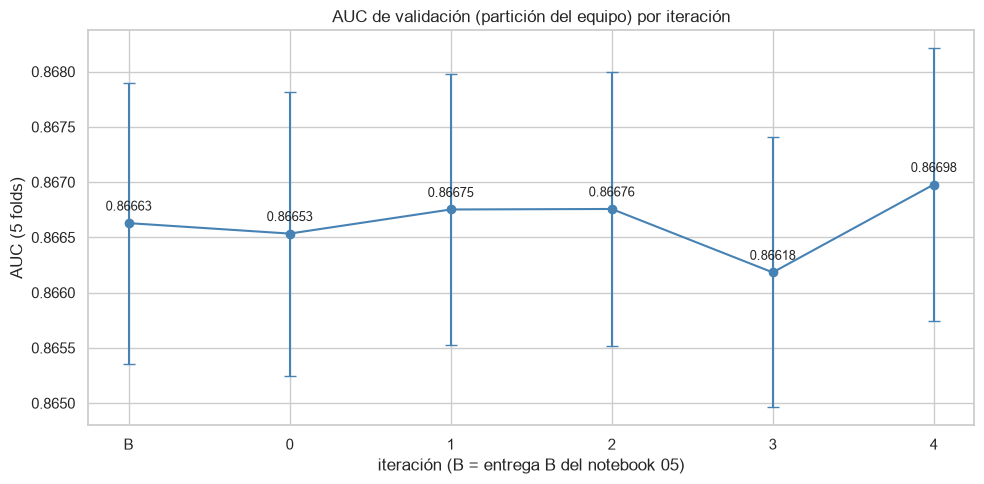

In [14]:
tabla_traza = pd.DataFrame(traza).set_index("iteración")
for clave in tabla_traza.index:
    comparacion = diferencia(resultados[clave].auc_folds, resultados["B"].auc_folds)
    tabla_traza.loc[clave, "Δ vs B"] = comparacion["Δ"]
    tabla_traza.loc[clave, "folds en que gana a B"] = comparacion["folds en que gana"]
SALIDA.mkdir(parents=True, exist_ok=True)
(SALIDA / "traza_07.json").write_text(
    json.dumps(
        {
            "iteraciones": tabla_traza.reset_index().to_dict(orient="records"),
            "variables_quitadas": QUITAR,
            "iteraciones_catboost": ITERACIONES_CB,
            "peso_catboost": PESO_CB,
        },
        ensure_ascii=False,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)
display(tabla_traza)

fig, ax = plt.subplots(figsize=(10, 5))
etiquetas = ["B", "0", "1", "2", "3", "4"]
medias = [resultados[k].auc_media for k in etiquetas]
errores = [resultados[k].auc_std / np.sqrt(5) for k in etiquetas]
ax.errorbar(etiquetas, medias, yerr=errores, marker="o", capsize=4, color="steelblue")
for etiqueta, valor in zip(etiquetas, medias, strict=True):
    ax.annotate(
        f"{valor:.5f}",
        (etiqueta, valor),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=9,
    )
ax.set_title("AUC de validación (partición del equipo) por iteración")
ax.set_xlabel("iteración (B = entrega B del notebook 05)")
ax.set_ylabel("AUC (5 folds)")
plt.tight_layout()
plt.show()

**Registro en la bitácora del equipo** (`reports/experiments.csv`). Se
reemplazan las filas que se registraron desde los scripts exploratorios;
`registrar_en_bitacora()` conserva el puntaje de Kaggle ya anotado.

In [15]:
DESCRIPCIONES = {
    "1": (DATASET_25, f"XGBoost 2b lr=0.01, {ARBOLES_JAE} árboles, 5 semillas"),
    "2": ("JAE 25 variables + FE", "mezcla 50/50 de jae_8 y jae_4"),
    "3": (
        "JAE 25 variables (como jae_8)",
        f"CatBoost lr=0.05, depth=6, l2=5, {ITERACIONES_CB} iteraciones, "
        "2 semillas en CV (5 en test)",
    ),
    "4": (
        "JAE 25 variables + FE",
        "mezcla por rangos: 70 % entrega D (jae_9) + 30 % CatBoost (jae_10)",
    ),
}
for clave, (features, modelo) in DESCRIPCIONES.items():
    registrar_en_bitacora(
        resultados[clave],
        features=features,
        modelo=modelo,
        notas=(
            f"notebooks/07_seleccion_catboost_jae; iteración {clave}; "
            f"AUC OOF {resultados[clave].auc_oof:.5f}"
        ),
    )
read_log().sort_values("cv_auc_mean", ascending=False)[
    ["nombre", "modelo", "cv_auc_mean", "cv_auc_std", "kaggle_score"]
].head(8)

,nombre,modelo,cv_auc_mean,cv_auc_std,kaggle_score
17,jae_11_entrega_f_catboost_w30,mezcla por rangos: 70 % entrega D (jae_9) + 30 % CatBoost (jae_10),0.86698,0.00275,0.88016
15,jae_9_entrega_d_mezcla,mezcla 50/50 de jae_8 y jae_4,0.86676,0.00277,0.87996
14,jae_8_seleccion_25_semillas,"XGBoost 2b lr=0.01, 764 árboles, 5 semillas",0.86675,0.00274,NaN
13,jae_7_entrega_c_mezcla,mezcla 50/50 de jae_6 y jae_4,0.86666,0.00284,NaN
10,jae_4_xgboost_fe_semillas,"XGBoost 2b lr=0.01, 777 árboles, 5 semillas",0.86663,0.00280,NaN
11,jae_5_entrega_b_mezcla,mezcla 50/50 de jae_3b y jae_4,0.86663,0.00285,0.88012
12,jae_6_interacciones_semillas,"XGBoost 2b lr=0.01, 764 árboles, 5 semillas",0.86653,0.00287,NaN
9,jae_3b_entrega_a_semillas,"XGBoost 2b lr=0.01, 764 árboles, 5 semillas",0.86638,0.00289,NaN


**Entregas.** Se reentrena cada modelo con todo `train` (5 semillas) y se
comparan las predicciones con los archivos que se subieron a Kaggle.

In [16]:
def predecir(
    crear: Callable[[int], object],
    X_entrenamiento: pd.DataFrame,
    X_prueba: pd.DataFrame,
) -> np.ndarray:
    """Reentrena con todo train por cada semilla y promedia en test.

    Args:
        crear: Función que recibe una semilla y devuelve el modelo sin ajustar.
        X_entrenamiento: Variables de todo ``train``.
        X_prueba: Variables de ``test``.

    Returns:
        Probabilidad promedio de las semillas para cada fila de ``test``.
    """
    return np.mean(
        [
            crear(s).fit(X_entrenamiento, y).predict_proba(X_prueba)[:, 1]
            for s in SEMILLAS
        ],
        axis=0,
    )


def guardar_entrega(valores: np.ndarray, archivo: str) -> pd.DataFrame:
    """Guarda una entrega con el formato de ``sample_submission.csv`` y la verifica.

    Args:
        valores: Probabilidad o rango de cada fila de ``test``.
        archivo: Nombre del archivo dentro de ``data/processed/jae/``.

    Returns:
        Entrega guardada.

    Raises:
        AssertionError: Si el formato no coincide con el de la muestra.
    """
    entrega = (
        pd.DataFrame({ID: test_raw[ID].to_numpy(), TARGET: valores})
        .set_index(ID)
        .loc[muestra[ID]]
        .reset_index()
    )
    assert list(entrega.columns) == list(muestra.columns), "Columnas distintas"
    assert len(entrega) == len(muestra), "Número de filas distinto"
    assert (
        entrega[ID].to_numpy() == muestra[ID].to_numpy()
    ).all(), "Orden de Id distinto"
    assert entrega[TARGET].notna().all(), "Hay valores nulos"
    assert entrega[TARGET].between(0, 1).all(), "Valores fuera de [0, 1]"
    entrega.to_csv(SALIDA / archivo, index=False)
    print(f"✅ {(SALIDA / archivo).relative_to(ROOT)}: {len(entrega):,} filas")
    return entrega


proba_25 = predecir(xgboost, X25, X25_test)
proba_fe = predecir(lambda s: xgboost(s, n_estimators=ARBOLES_FE), X_fe, X_fe_test)
proba_cb = predecir(catboost, X25, X25_test)
n_test = len(test_raw)
valores_d = (proba_25 + proba_fe) / 2
valores_f = ((1 - PESO_CB) * rankdata(valores_d) + PESO_CB * rankdata(proba_cb)) / (
    n_test + 1
)

subidas = {
    "D": ("submission_d_mezcla_seleccion.csv", valores_d),
    "F": ("submission_f_catboost_w30.csv", valores_f),
}
filas = []
for entrega, (archivo, valores) in subidas.items():
    subida = pd.read_csv(SALIDA / archivo).set_index(ID)[TARGET].loc[test_raw[ID]]
    filas.append(
        {
            "entrega": entrega,
            "archivo subido": archivo,
            "diferencia máxima": float(np.abs(subida.to_numpy() - valores).max()),
            "Spearman": subida.corr(
                pd.Series(valores, index=subida.index), method="spearman"
            ),
        }
    )
    guardar_entrega(valores, archivo.replace(".csv", "_nb07.csv"))
display(pd.DataFrame(filas).set_index("entrega"))
pd.DataFrame(
    {
        ID: train_raw[ID],
        "oof_entrega_d": resultados["2"].oof,
        "oof_catboost": oof_cb["equipo"],
        "oof_entrega_f": resultados["4"].oof,
        TARGET: y,
    }
).to_parquet(SALIDA / "oof_seleccion_catboost_07.parquet", index=False)
print(f"Tiempo total: {time.time() - INICIO:.0f} s")

✅ data/processed/jae/submission_d_mezcla_seleccion_nb07.csv: 45,000 filas
✅ data/processed/jae/submission_f_catboost_w30_nb07.csv: 45,000 filas


,archivo subido,diferencia máxima,Spearman
entrega,,,
D,submission_d_mezcla_seleccion.csv,2.978821e-08,1.0
F,submission_f_catboost_w30.csv,2.604109e-08,1.0


Tiempo total: 2493 s


**Lectura:** las entregas D y F regeneradas con este notebook
coinciden con los archivos que se subieron a Kaggle (diferencia máxima de
3e-8 y el mismo orden). Las copias se guardan con el sufijo `_nb07` en
`data/processed/jae/`, que no se versiona.

## 9. Conclusiones

| Entrega | AUC validación cruzada | Kaggle público |
| --- | --- | --- |
| B (notebook 05) | 0.86663 | 0.88012 |
| D: JAE 25 variables + FE | 0.86676 | 0.87996 |
| **F: 70 % D + 30 % CatBoost** | **0.86698** | **0.88016** |

1. **Quitar variables redundantes ayudó, pero solo dos.** Sin
   `disposable_income_clip` ni `total_late`, el XGBoost JAE mejora +0.00022
   y la mejora se confirma en una partición independiente. Quitar grupos
   completos o más variables no ayuda.
2. **El problema no era la dimensionalidad, sino la redundancia.** Con
   105,000 clientes y 27 variables no hay maldición de la dimensionalidad;
   lo que pasa es que el muestreo de columnas reparte los árboles entre
   variables casi idénticas.
3. **Las restricciones monótonas empeoran** en las dos particiones.
4. **CatBoost aporta diversidad real.** Solo es peor que XGBoost, pero en
   mezcla (30 %) mejora la entrega D en los 5 folds. Es la mayor mejora
   desde el notebook 05.
5. **La entrega F fue la mejor en el leaderboard público (0.88016) y el
   equipo mantuvo el tercer lugar en el privado.**
6. **El puntaje público es ruidoso** (desviación estándar de 0.004 a 0.006):
   la selección de entregas se hace con la validación cruzada y con una
   partición independiente que no se usó para elegir.